In [2]:
import pandas as pd

In [3]:
orders= pd.read_csv("C:/Users/SHRUTI/Desktop/Demand Forecasting/data/olist/olist_orders_dataset.csv")

In [4]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
print(orders.shape)

(99441, 8)


In [6]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [7]:
orders["order_purchase_timestamp"]=pd.to_datetime(orders["order_purchase_timestamp"])

In [8]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  str           
 5   order_delivered_carrier_date   97658 non-null  str           
 6   order_delivered_customer_date  96476 non-null  str           
 7   order_estimated_delivery_date  99441 non-null  str           
dtypes: datetime64[us](1), str(7)
memory usage: 6.1 MB


In [9]:
print(orders["order_purchase_timestamp"].min())
print(orders["order_purchase_timestamp"].max())

2016-09-04 21:15:19
2018-10-17 17:30:18


In [10]:
weekly= orders.set_index("order_purchase_timestamp").resample("W").size()
weekly.head(10)

order_purchase_timestamp
2016-09-04      1
2016-09-11      1
2016-09-18      2
2016-09-25      0
2016-10-02      1
2016-10-09    283
2016-10-16     39
2016-10-23      1
2016-10-30      0
2016-11-06      0
Freq: W-SUN, dtype: int64

In [11]:
import matplotlib.pyplot as plt

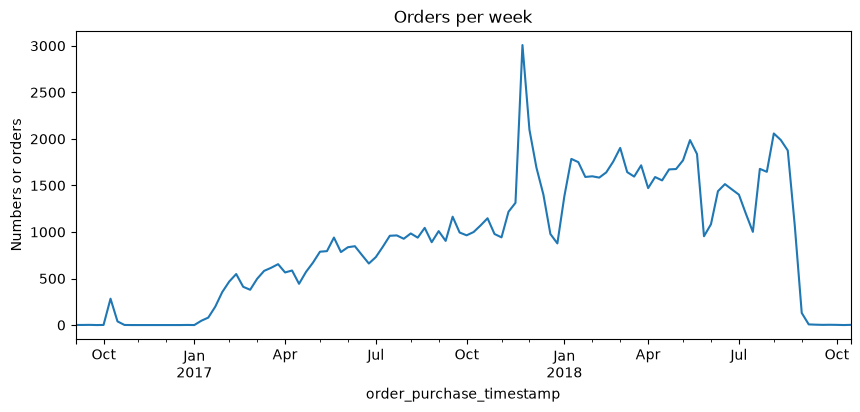

In [12]:
weekly.plot(figsize=(10,4))
plt.title("Orders per week")
plt.ylabel("Numbers or orders")
plt.show()

In [13]:
weekly.tail(10)

order_purchase_timestamp
2018-08-19    1875
2018-08-26    1071
2018-09-02     130
2018-09-09       7
2018-09-16       4
2018-09-23       2
2018-09-30       3
2018-10-07       2
2018-10-14       0
2018-10-21       2
Freq: W-SUN, dtype: int64

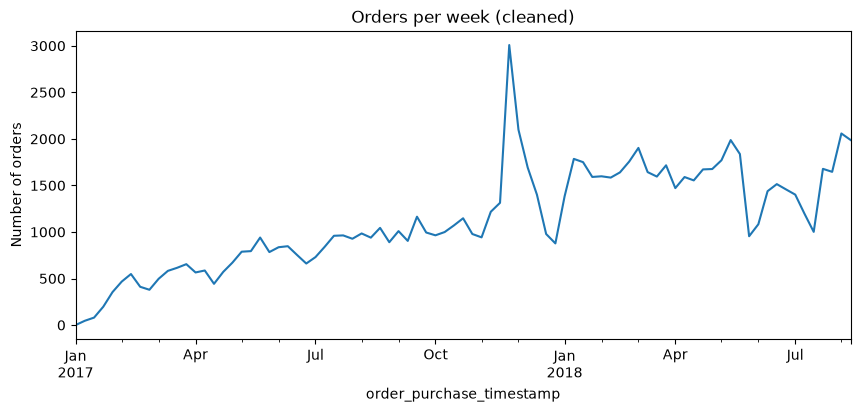

In [14]:
weekly_clean= weekly["2017-01-01":"2018-08-12"]
weekly_clean.plot(figsize=(10,4))
plt.title("Orders per week (cleaned)")
plt.ylabel("Number of orders")
plt.show()

In [15]:
len(weekly_clean)

85

In [16]:
train = weekly_clean[:-12]

In [17]:
test = weekly_clean[-12:]

In [18]:
print(len(train), len(test))

73 12


In [21]:
print(train.name)
print(train.index)
print(train.values)

None
DatetimeIndex(['2017-01-01', '2017-01-08', '2017-01-15', '2017-01-22',
               '2017-01-29', '2017-02-05', '2017-02-12', '2017-02-19',
               '2017-02-26', '2017-03-05', '2017-03-12', '2017-03-19',
               '2017-03-26', '2017-04-02', '2017-04-09', '2017-04-16',
               '2017-04-23', '2017-04-30', '2017-05-07', '2017-05-14',
               '2017-05-21', '2017-05-28', '2017-06-04', '2017-06-11',
               '2017-06-18', '2017-06-25', '2017-07-02', '2017-07-09',
               '2017-07-16', '2017-07-23', '2017-07-30', '2017-08-06',
               '2017-08-13', '2017-08-20', '2017-08-27', '2017-09-03',
               '2017-09-10', '2017-09-17', '2017-09-24', '2017-10-01',
               '2017-10-08', '2017-10-15', '2017-10-22', '2017-10-29',
               '2017-11-05', '2017-11-12', '2017-11-19', '2017-11-26',
               '2017-12-03', '2017-12-10', '2017-12-17', '2017-12-24',
               '2017-12-31', '2018-01-07', '2018-01-14', '2018-01-21',
 

In [22]:
naive_pred= weekly_clean.shift(1).iloc[-12:]

In [23]:
naive_pred

order_purchase_timestamp
2018-05-27    1837.0
2018-06-03     954.0
2018-06-10    1083.0
2018-06-17    1438.0
2018-06-24    1514.0
2018-07-01    1457.0
2018-07-08    1401.0
2018-07-15    1196.0
2018-07-22    1001.0
2018-07-29    1678.0
2018-08-05    1646.0
2018-08-12    2058.0
Freq: W-SUN, dtype: float64

In [24]:
ma_pred= weekly_clean.rolling(4).mean().shift(1).iloc[-12:]

In [25]:
print("Moving average prediction:")
print(ma_pred)

Moving average prediction:
order_purchase_timestamp
2018-05-27    1817.50
2018-06-03    1637.00
2018-06-10    1465.25
2018-06-17    1328.00
2018-06-24    1247.25
2018-07-01    1373.00
2018-07-08    1452.50
2018-07-15    1392.00
2018-07-22    1263.75
2018-07-29    1319.00
2018-08-05    1380.25
2018-08-12    1595.75
Freq: W-SUN, dtype: float64


In [28]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
from sklearn.metrics import mean_absolute_error

In [31]:
ma_mae= mean_absolute_error(test,ma_pred)

In [32]:
print("MAE: ",ma_mae)

MAE:  360.6041666666667


In [34]:
naive_mae= mean_absolute_error(test,naive_pred)

In [35]:
print("Naive_mae:",naive_mae)

Naive_mae: 262.25


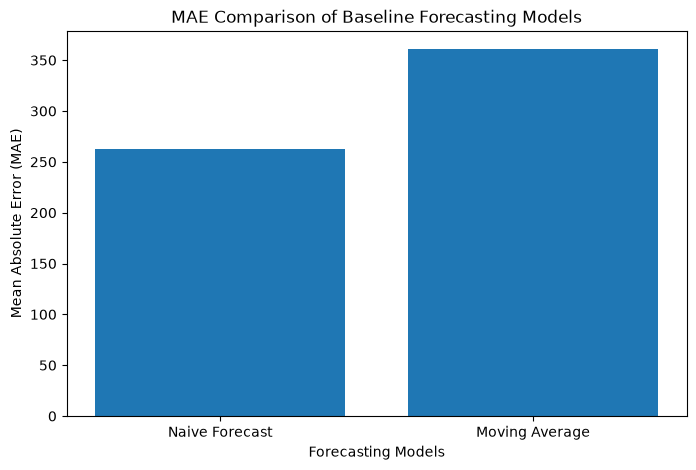

In [38]:
import matplotlib.pyplot as plt

models= ["Naive Forecast", "Moving Average"]
mae_values=[naive_mae,ma_mae]

plt.figure(figsize=(8,5))

plt.bar(models,mae_values)

plt.title("MAE Comparison of Baseline Forecasting Models")
plt.xlabel("Forecasting Models")
plt.ylabel("Mean Absolute Error (MAE)")

plt.show()

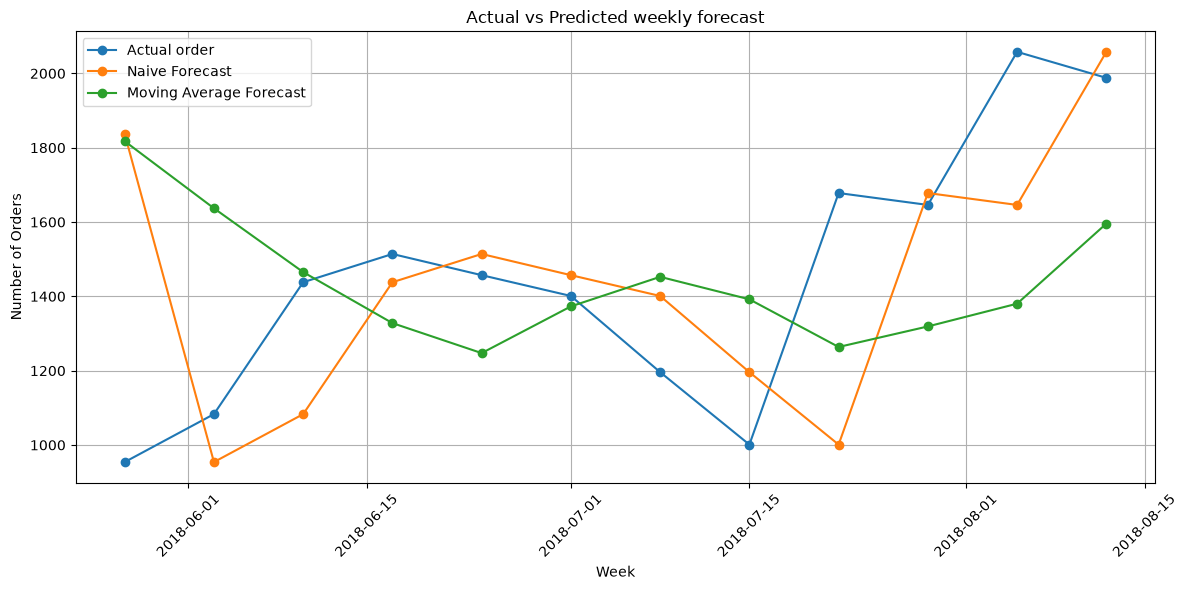

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(test.index,test,marker='o',label="Actual order")

plt.plot(naive_pred.index, naive_pred, marker='o', label="Naive Forecast")
plt.plot(ma_pred.index, ma_pred, marker='o',label="Moving Average Forecast")

plt.title("Actual vs Predicted weekly forecast")
plt.xlabel("Week")
plt.ylabel("Number of Orders")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()